In [7]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import stream_fnspid_slice


In [8]:
TICKER = "TSLA"
START_DATE = pd.Timestamp("2019-01-01", tz="UTC")
END_DATE = pd.Timestamp("2024-01-01", tz="UTC")

DATASET_NAME = (
    "benstaf/FNSPID-nasdaq-100-post2019-1newsperrow"
)

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
figures_dir = project_root / "outputs" / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Streaming {TICKER} records from FNSPID subset...")

Streaming TSLA records from FNSPID subset...


In [9]:

news_stream = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

selected_rows = []

for row in tqdm(
    news_stream,
    desc="Reading news records"
):
    stock_symbol = str(
        row.get("Stock_symbol", "")
    ).strip().upper()

    if stock_symbol != TICKER:
        continue

    article_date = pd.to_datetime(
        row.get("Date"),
        errors="coerce",
        utc=True
    )

    if pd.isna(article_date):
        continue

    if not (START_DATE <= article_date < END_DATE):
        continue

    headline = str(
        row.get("Article_title", "")
    ).strip()

    if not headline:
        continue

    selected_rows.append(
        {
            "Date": article_date,
            "Article_title": headline,
            "Stock_symbol": stock_symbol,
            "Url": row.get("Url"),
            "Publisher": row.get("Publisher")
        }
    )

print("Matching records found:", len(selected_rows))

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sarth\.cache\huggingface\hub\datasets--benstaf--FNSPID-nasdaq-100-post2019-1newsperrow. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Reading news records: 61827

Matching records found: 872


In [10]:

news_df = pd.DataFrame(selected_rows)

news_df = news_df.drop_duplicates(
    subset=["Date", "Article_title", "Stock_symbol"]
)

news_df = news_df.sort_values("Date").reset_index(drop=True)

print("Final record count:", len(news_df))
print("Date range:", news_df["Date"].min(), "to", news_df["Date"].max())

display(news_df.head())
display(news_df.tail())

Final record count: 872
Date range: 2019-07-01 00:00:00+00:00 to 2023-12-16 22:00:00+00:00


,Date,Article_title,Stock_symbol,Url,Publisher
0,2019-07-01 00:00:00+00:00,Tesla's Q2 Delivery Number Could Cause A Big Move,TSLA,https://www.benzinga.com/analyst-ratings/analy...,Wayne Duggan
1,2019-07-02 00:00:00+00:00,"Tesla, Unum Therapeutics Making Big Moves In T...",TSLA,https://www.benzinga.com/news/19/07/14022507/t...,Brett Hershman
2,2019-07-03 00:00:00+00:00,Big Tesla Options Trades Could Signal Institut...,TSLA,https://www.benzinga.com/markets/options/19/07...,Wayne Duggan
3,2019-07-05 00:00:00+00:00,'Tesla reduces the price of its solar systems'...,TSLA,https://www.benzinga.com/news/19/07/14035083/t...,Benzinga_Newsdesk
4,2019-07-06 00:00:00+00:00,"Barron's Picks And Pans: Coca-Cola, Kroger, Sh...",TSLA,https://www.benzinga.com/media/19/07/14036491/...,Nelson Hem


,Date,Article_title,Stock_symbol,Url,Publisher
867,2023-12-12 00:00:00+00:00,TSLA Factor-Based Stock Analysis,TSLA,https://www.nasdaq.com/articles/tsla-factor-ba...,
868,2023-12-13 00:00:00+00:00,Why Tesla's Cheap (2024 Outlook),TSLA,https://www.nasdaq.com/articles/why-teslas-che...,
869,2023-12-14 00:00:00+00:00,Tesla Stock Can Soar in 2024 if It Does These ...,TSLA,https://www.nasdaq.com/articles/tesla-stock-ca...,
870,2023-12-15 00:00:00+00:00,Elon Musk says oil and gas should not be demon...,TSLA,https://www.nasdaq.com/articles/elon-musk-says...,
871,2023-12-16 22:00:00+00:00,Scotiabank's Mexico bet eyeing $1.6 trillion N...,TSLA,https://www.nasdaq.com/articles/scotiabanks-me...,


year
2019    143
2020    141
2022    241
2023    347
Name: count, dtype: int64


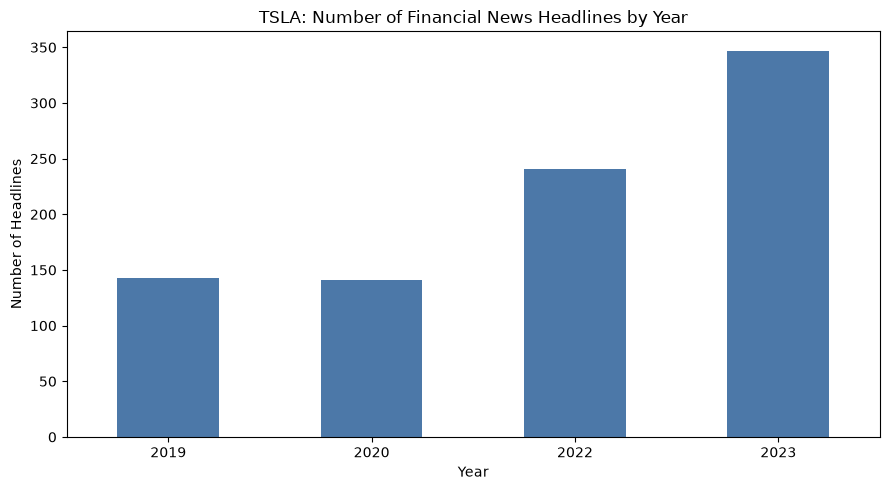

In [11]:

news_df["year"] = news_df["Date"].dt.year

year_counts = news_df["year"].value_counts().sort_index()

print(year_counts)

plt.figure(figsize=(9, 5))

year_counts.plot(
    kind="bar",
    color="#4C78A8"
)

plt.title(f"{TICKER}: Number of Financial News Headlines by Year")
plt.xlabel("Year")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    figures_dir / f"{TICKER.lower()}_news_coverage_by_year.png",
    dpi=200
)

plt.show()

year
2019    143
2020    141
2022    241
2023    347
Name: count, dtype: int64


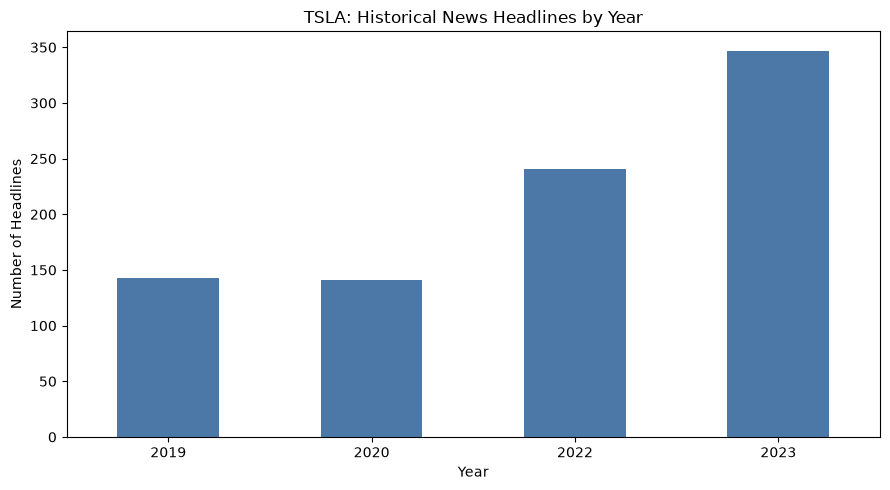

In [12]:

news_df["year"] = news_df["Date"].dt.year

year_counts = news_df["year"].value_counts().sort_index()

print(year_counts)

plt.figure(figsize=(9, 5))

year_counts.plot(
    kind="bar",
    color="#4C78A8"
)

plt.title(f"{TICKER}: Historical News Headlines by Year")
plt.xlabel("Year")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    figures_dir / f"{TICKER.lower()}_news_coverage_by_year.png",
    dpi=200
)

plt.show()

In [13]:

output_file = (
    processed_dir
    / f"fnspid_{TICKER.lower()}_2019_2023.csv"
)

news_df.to_csv(output_file, index=False)

print("Saved filtered news file:")
print(output_file)

Saved filtered news file:
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\data\processed\fnspid_tsla_2019_2023.csv
